In [1]:
'''
For the Rubin Science Platform at data.lsst.cloud.
Data Release: Data Preview 1
Container Size: large
LSST Science Pipelines version: r29.2.0
Last verified to run: 2025-10-29
Repository: github.com/lsst/tutorial-notebooks
DOI: 10.11578/rubin/dc.20250909.20
'''
#Originally developed by Andrés A. Plazas Malagón and the Rubin Community Science team with input from Nate Lust. 

#Learning objective: Create a large custom `deep_coadd` cutout.

#LSST data products: `deep_coadd`.

#Packages: `lsst.daf.butler`, `lsst.ip.diffim.GetTemplateTask`.


'\nFor the Rubin Science Platform at data.lsst.cloud.\nData Release: Data Preview 1\nContainer Size: large\nLSST Science Pipelines version: r29.2.0\nLast verified to run: 2025-10-29\nRepository: github.com/lsst/tutorial-notebooks\nDOI: 10.11578/rubin/dc.20250909.20\n'

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as mcm
from astropy.io import fits
import pandas as pd
import astropy.wcs as wcs
from astropy.coordinates import SkyCoord
from astropy import units as u

from lsst.rsp import get_tap_service
from lsst.daf.butler import Butler
import lsst.afw.display as afwDisplay
from lsst.afw.detection import InvalidPsfError

from lsst.geom import Box2I, Point2I, SpherePoint, degrees, Point2D
from lsst.sphgeom import Box as SphBox

from lsst.ip.diffim import GetTemplateTask
from lsst.pipe.tasks.makeDiscreteSkyMap import MakeDiscreteSkyMapTask

#`GetTemplateTask` (`lsst.ip.diffim`) retrieves template images for image differencing, 
# while `lsst.pipe.tasks.makeDiscreteSkyMap` generates discrete sky maps for defining sky coverage.

In [3]:
butler = Butler("dp1", collections="LSSTComCam/DP1") #Instantiate the butler.
assert butler is not None

skymap = butler.get("skyMap") #Define the skymap.
username = os.environ.get('USER')

#sources = pd.read_csv('/home/' + username + '/lsst_science/ECFDS_LSBGs.csv')
#print(sources.shape)

sample = pd.read_csv('v1sdwarf_list.csv')
print(sample.shape)

(14701, 6)


In [4]:
service = get_tap_service("tap")
assert service is not None

query = "SELECT lsst_tract,lsst_patch,s_ra,s_dec, s_region " \
        "FROM dp1.CoaddPatches " 
results = service.search(query).to_table().to_pandas()
print(results.shape)

(652, 5)


In [8]:
bands = {'u':mcm.magma,'g':mcm.cividis,'r':mcm.viridis,'i':mcm.inferno,'z':mcm.Greys_r}
box_size_deg = 0.004 #Define a box size of 0.1 degrees around the BCG, then search for all patches within twice that size (2 * `box_size_deg`).

def gen_smallbox(nwcs,ra,dec):
        return  Box2I(
        Point2I(nwcs.skyToPixel(SpherePoint(ra - box_size_deg,
                                               dec - box_size_deg, degrees))),
        Point2I(nwcs.skyToPixel(SpherePoint(ra + box_size_deg,
                                               dec + box_size_deg, degrees))),
        )     #Create a bounding box in the new WCS coordinates that is centered on the BCG and has the width defined above.

def gen_wcsbox(pos_cont,point):
    cd_wcs = pos_cont[0][0]
    discrete_skymap_config = MakeDiscreteSkyMapTask().ConfigClass() #Make a skymap that contains all input data.
    discrete_skymap_config.skyMap.pixelScale = cd_wcs.getPixelScale(Point2D(point)).asArcseconds() #Set the plate scale at the BCG location in the new skymap.
    discrete_skymap_config.skyMap.projection = 'TAN' #Set the WCS projection type. The WCS of `deep_coadd` images are `TAN` projections([see the DP1 documentation]

    new_skymap = MakeDiscreteSkyMapTask(config=discrete_skymap_config).run(pos_cont).skyMap #Compute the new skymap.
    new_wcs = new_skymap[0].wcs     #Get the new WCS from the single tract discrete skymap.
    small_box = gen_smallbox(new_wcs,(point.getRa()).asDegrees(),(point.getDec()).asDegrees())

    return new_wcs,small_box
    

def reconstitute_fits(uname,ra,dec,objid):
    img_arr = [[],[],[]]
    
    for ii, key in enumerate(bands):    
            fnm = '/home/' + uname + '/lsst_science/cutouts/temp_{}.fits'.format(key)
            hdul = fits.open(fnm)
            w = wcs.WCS(hdul[0].header)
            pos_coord = SkyCoord(ra=ra*u.degree, dec=dec*u.degree, frame='icrs')
            wc = [int(i) for i in w.world_to_pixel(pos_coord)]
            if ii==0:    img_hdr = [hdul[j].header for j in range(1,4)]
            for j in range(3): img_arr[j].append((hdul[j+1].data)[wc[1]-64:wc[1]+64,wc[0]-64:wc[0]+64])
        
            hdul.close()
            os.remove(fnm)
    #fnm = '/home/' + uname + '/lsst_science/cutouts/cutout_{:.6f}_{:.6f}.fits'.format(ra,dec)
    #fits.writeto(fnm, np.array(img_arr[0]), header=img_hdr[0],overwrite=True)
    #for j in [1,2]: fits.append(fnm, np.array(img_arr[j]), img_hdr[j]) 

    #for i in range(5): img_arr[0][i] = 255*(img_arr[0][i] - np.amin(img_arr[0][i]))/(np.amax(img_arr[0][i])-np.amin(img_arr[0][i]))

    fnm = '/home/' + uname + f'/lsst_science/cutouts/cutout_{int(objid)}.npy'
    data_uint8 = np.array(img_arr[0])

    np.save(fnm, data_uint8)

In [6]:
unique_patch = sample['patch'].unique()
print(unique_patch)

[24 25 23 35 34 33 44 43 45]


In [9]:
#Get the dataset references in the `r` band.

for ll,up in enumerate(unique_patch):
    inpatch = sample[sample['patch']==up]
    print(inpatch.shape)
    tp_link = results[(results['lsst_tract']==sample['tract'][0])&(results['lsst_patch']==up)]
    s_ra,s_dec = (tp_link['s_ra'].values)[0],(tp_link['s_dec'].values)[0]
    print(s_ra,s_dec)

    #sorted_data = {}
    coadd_get,did_get = {},{}
    for jj,filt in enumerate(bands):
            query = f"patch.region OVERLAPS POINT({s_ra}, {s_dec}) and band in ('{filt}')"
            try:
                qry_ds = butler.query_datasets("deep_coadd",where=query)
            except: continue                     
            #band_container = sorted_data.setdefault(did["band"], list())
            #band_container.append()
        
            did_get[filt] = qry_ds[0].dataId
            coadd_get[filt] = butler.get(qry_ds[0])

            patchInfo = skymap[did_get[filt]["tract"]][did_get[filt]["patch"]]
            if filt=='g': position_container = [(patchInfo.wcs, patchInfo.outer_bbox)]
    
    for ii, src in inpatch.iterrows():
        ra,dec = src['ra'], src['dec']
        point = SpherePoint(ra * degrees,dec * degrees)
        #tract = skymap.findTract(point)
        #patch = tract.findPatch(point)
        #tract_number,patch_number = tract.tract_id,patch.getSequentialIndex()
        tract_number,patch_number = int(src['tract']),int(src['patch'])
        print(ii,ra,dec,tract_number,patch_number)

        new_wcs,small_box = gen_wcsbox(position_container,point)
    
        #fig,ax=plt.subplots(1,5,figsize=(30,8))
    
        for jj,filt in enumerate(bands):
            #coadd = butler.get(mapping[tract_number][0]) #Get the coadd from the data reference.
            #cd_wcs = coadd.getWcs()  #Get the WCS from the coadd.
       
            #Create a new coadd image in the band defined above that is a combination of the inputs contained within the defined box. 
            #Note that the run method modifies the bounding box in place, so a copy is made.
            getTemplateTask = GetTemplateTask()
            new_image = getTemplateTask.run(
            coaddExposures={tract_number:[coadd_get[filt]]},
            bbox=Box2I(small_box),wcs=new_wcs,
            dataIds={tract_number:[did_get[filt]]},
            physical_filter=filt,)
        
            fnm = '/home/' + username + '/lsst_science/cutouts/temp_{}.fits'.format(filt)
            afwDisplay.writeFitsImage(fnm,  new_image.template.maskedImage,  wcs=new_image.template.wcs)
        
            img_array = new_image.template.image.array
                
            m, s = np.mean(img_array), np.std(img_array)
            #ax[jj].imshow(img_array, interpolation='nearest', cmap=bands[filt], vmin=m-s, vmax=m+s, origin='lower')
    
            del img_array,m,s
        
            #fnm = '/home/' + username + '/lsst_science/cutouts/cutout_{:.5f}_{:.5f}_{}.fits'.format(ra,dec,filt)
            #new_image.template.writeFits(fnm)
            del fnm,new_image
        reconstitute_fits(username,ra,dec,src['objid'])
        #plt.show()


(2927, 6)
53.181849243777485 -27.937259079179512
0 53.093012 -27.954546 5063 24


1 53.101709 -27.958481 5063 24


2 53.104511 -27.957059 5063 24


3 53.102331 -27.956404 5063 24


4 53.090861 -27.95642 5063 24


...

14161 53.278419 -27.685534 5063 43


14166 53.277953 -27.685343 5063 43


14188 53.283896 -27.684961 5063 43


14191 53.281592 -27.684674 5063 43


14207 53.278291 -27.684338 5063 43


In [38]:
data = np.load('cutouts/cutout_53.224573_-27.583221.npy')

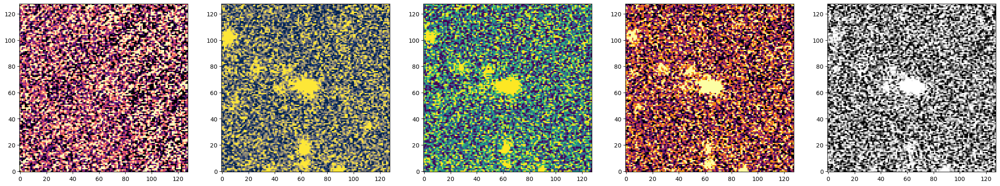

In [39]:
fig,ax=plt.subplots(1,5,figsize=(30,8))

for i,filt in enumerate(bands):
    m, s = np.mean(data[i,:,:]), np.std(data[i,:,:])
    ax[i].imshow(data[i,:,:], interpolation='nearest', cmap=bands[filt], vmin=m-s, vmax=m+s, origin='lower')
    

## 3. Create the cutout

In [23]:
'''
        SIGMA_TO_FWHM = 2.0*np.sqrt(2.0*np.log(2.0))
    
        center_pix_new = new_wcs.skyToPixel(point)
        point_new = Point2D(center_pix_new)
        newimage_psf = new_image.template.getPsf()
        psf_sigma_new = newimage_psf.computeShape(point_new).getDeterminantRadius()
    
        print(f"newimage FWHM = {psf_sigma_new * SIGMA_TO_FWHM: .3f} pixels")
        '''

<module 'astropy.wcs' from '/opt/lsst/software/stack/conda/envs/lsst-scipipe-10.1.0/lib/python3.12/site-packages/astropy/wcs/__init__.py'>


AttributeError: 'WCS' object has no attribute 'skyToPixel'

Create an image of an arbitrary sky region that is not aligned with the native Legacy Survey of Space and Time (LSST) sky tessellation.
This is similar to the process in alert production, where past LSST observations are combined to generate static-sky templates for detecting transients in new exposures.
The same template-generation code (`GetTemplateTask`) can be used to transform input data aligned on the LSST tessellation into the required geometry.

To use the template code, a single astrometric solution or World Coordinate System (WCS) that encompasses all input data is needed, instead of having a separate tangent-plane WCS for each tract.
A new and custom discrete skymap is therefore created for the input data, producing one tract with a single WCS projection.
A bounding box is then defined in these new coordinates, centered on the brightest cluster galaxy (BCG) and spanning the specified width.

With this setup, images are generated per band by combining the inputs that fall within the bounding box. The `GetTemplateTask` creates coadds for each band.

Prepare the inputs for building the custom skymap.

For each dataset reference, the WCS and bounding box of its patch are stored, so the collection of positions can later define the custom skymap that includes only the data in use.
At the same time, the dataset references are organized into a nested dictionary: first grouped by band, then within each band grouped by tract.
Each tract key contains all the dataset refs for that tract band combination.

> Figure 1: Cutout of the Abell 360 cluster, displayed using `matplotlib` as backend for `awf.display`. Note that the coordinates are in pixel units.